The repeated failures (`Py4JNetworkError`) were caused by **insufficient memory allocated to Docker Desktop**, which made the Spark driver crash when processing large files.

**Please follow these steps exactly:**
1.  **Adjust Docker memory**:
    *   Locate the Docker whale icon in your system tray (bottom-right on Windows).
    *   Right-click it -> **Settings**.
    *   Left menu -> **Resources**.
    *   Find the **Memory** slider and **set it to at least 10 GB** (12 GB recommended if your machine has 16 GB or more).
    *   Click **Apply & Restart**.
     # OR
    * WIN + R -> %USERPROFILE%
    * create a file named .wslconfig
    * add the following line to the file:

In [ ]:
    [wsl2]
    memory=12GB

2.  **Restart the notebook kernel**:
    *   After Docker has restarted, return to this page. 
    *   Follow the hint in Phase 1&2 to restart the kernel.
3.  **Run the cells below in order**.
4.  **Please don't run the second cell only if you have to**.

**if you are fluently aborted from the JVM, please follow the step above**

## [README]
This notebook require docker desktop.

once downloaded, type the following command in the terminal:

In [ ]:
docker-compose up -d

Once the command is executed, type the following command in the terminal to get the token:

In [ ]:
docker logs jupyter_analytics

Find the token in the terminal outputs, it would look like this:

**http://127.0.0.1:8888/lab?token=XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX**

Note: the ip address might be different

Copy that token link. Then, go to your notebook and click **Select Kernel** in the top-right corner.

Go to **Select Another Kernel...** > **Existing Jupyter Server...** and paste your token in the input box.

Hit Enter, then Enter again... and you're in!




Please run the first cell to initialize the spark,

If you make a mistake in editing the following cells, no worries — just switch the second cell from Markdown to Python,

run it, and switch it back.

The following cells are just AI generated and serve as a runnable skeleton.

The actual implementation details and business logic need to be carefully filled in by each student.





# PHASE 3 Data Storage and Cleansing

In [1]:
# ==========================================
# Robust Spark Session Init (8GB RAM)
# ==========================================
import os
from pyspark.sql import SparkSession

# 1. Set HDFS Identity to 'root' for full permissions
os.environ['HADOOP_USER_NAME'] = 'root'
os.chdir('/home/jovyan/work')

# 2. Stop any existing session
if SparkSession.getActiveSession():
    SparkSession.getActiveSession().stop()

# 3. Initialize Spark with 8GB Memory
spark = SparkSession.builder \
    .appName("Phase3_Process_Storage") \
    .master("local[*]") \
    .config("spark.driver.memory", "8g") \
    .config("spark.executor.memory", "8g") \
    .config("spark.memory.offHeap.enabled", "true") \
    .config("spark.memory.offHeap.size", "2g") \
    .config("spark.hadoop.fs.defaultFS", "hdfs://namenode:9000") \
    .config("spark.sql.caseSensitive", "true") \
    .getOrCreate()

print(f"✅ Spark Ready! Driver Memory: 8g")

✅ Spark Ready! Driver Memory: 8g


#Do NOT run this cell only if you crush the data

#Press Enter and change markdown to python when you decide to run this cell

print("🧹 Wiping HDFS /ecommerce...")
try:
    fs = spark._jvm.org.apache.hadoop.fs.FileSystem.get(spark._jsc.hadoopConfiguration())
    fs.delete(spark._jvm.org.apache.hadoop.fs.Path("/ecommerce"), True)
    print("✅ HDFS Cleaned.")
except Exception as e:
    print(f"❌ Cleanup failed: {e}")

In [ ]:
# ==========================================
# Sync Local Data to HDFS (with MORE Partitions)
# ==========================================
# Ensure data extracted to data_lake folder

with open("datasets.txt", 'r') as f:
    lines = [line.strip() for line in f if line.strip()]

datasets = [
    (f"data_lake/{types}_{line.split(',')[0].strip()}.parquet", f"/ecommerce/data_lake/{types}/{types}_{line.split(',')[1].strip()}")
    for types in ['meta', 'review']
    for line in lines
]

for local_p, hdfs_p in datasets:
    if os.path.exists(local_p):
        print(f"🚚 Syncing {local_p}...")
        # Repartition MORE to manage memory usage for large files
        # This splits the data into 32 smaller chunks before writing
        df = spark.read.parquet(f"file://{os.path.abspath(local_p)}").repartition(32)
        df.write.mode("overwrite").parquet(hdfs_p)
        print(f"   ✅ Done: {hdfs_p}")
    else:
        print(f"   ❌ Local file not found: {local_p}")

print("\n✨ Data synchronization complete!")

🚚 Syncing data_lake/meta_Electronics_clean.parquet...
   ✅ Done: /ecommerce/data_lake/meta/meta_elec
🚚 Syncing data_lake/meta_Cell_Phones_and_Accessories_clean.parquet...
   ✅ Done: /ecommerce/data_lake/meta/meta_cellp
🚚 Syncing data_lake/review_Electronics_clean.parquet...
   ✅ Done: /ecommerce/data_lake/review/review_elec
🚚 Syncing data_lake/review_Cell_Phones_and_Accessories_clean.parquet...
   ✅ Done: /ecommerce/data_lake/review/review_cellp

✨ Data synchronization complete!


In [3]:
meta_path = "/ecommerce/data_lake/meta/*"
review_path = "/ecommerce/data_lake/review/*"

def preview_parquet(label, path):
    print(f"\n=== {label} ===")
    print(f"Path: {path}")
    df = spark.read.parquet(path)
    print(f"Columns ({len(df.columns)}): {df.columns}")
    df.printSchema()
    df.limit(5).show(5, truncate=60)
    try:
        print(f"Partitions: {df.rdd.getNumPartitions()}")
    except Exception:
        pass

preview_parquet("RAW META (HDFS)", meta_path)
preview_parquet("RAW REVIEW (HDFS)", review_path)

print("\n✅ Data preview finished (no full count performed).")


=== RAW META (HDFS) ===
Path: /ecommerce/data_lake/meta/*
Columns (16): ['author', 'average_rating', 'bought_together', 'categories', 'description', 'details', 'features', 'images', 'main_category', 'parent_asin', 'price', 'rating_number', 'store', 'subtitle', 'title', 'videos']
root
 |-- author: struct (nullable = true)
 |    |-- about: array (nullable = true)
 |    |    |-- element: string (containsNull = true)
 |    |-- avatar: string (nullable = true)
 |    |-- name: string (nullable = true)
 |-- average_rating: double (nullable = true)
 |-- bought_together: string (nullable = true)
 |-- categories: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- description: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- details: struct (nullable = true)
 |    |-- AC Adapter Current: string (nullable = true)
 |    |-- Accessory Connection Type: string (nullable = true)
 |    |-- Action: string (nullable = true)
 |    |-- Active Ingredient

In [ ]:
# ==========================================
# Data Preview
# ==========================================
import os

DATA_LAKE = "/home/jovyan/work/data_lake"

with open("datasets.txt", 'r') as f:
    lines = [line.strip() for line in f if line.strip()]

files = {
    f"{types}_{line.split(',')[0].strip()}" : f"{types}_{line.split(',')[0].strip()}.parquet"
    for types in ["meta", "review"]
    for line in lines
}

# "meta_Electronics": "meta_Electronics_clean.parquet",
#     "meta_Cell_Phones": "meta_Cell_Phones_and_Accessories_clean.parquet",
#     "review_Electronics": "review_Electronics_clean.parquet",
#     "review_Cell_Phones": "review_Cell_Phones_and_Accessories_clean.parquet",

def preview_local_parquet(name, path):
    if not os.path.exists(path):
        print(f"⚠️  [{name}] not found: {path}")
        return

    size_mb = os.path.getsize(path) / (1024 * 1024)
    df = spark.read.parquet(f"file://{path}")

    print(f"\n{'='*60}")
    print(f"📋 {name}")
    print(f"{'='*60}")
    print(f"   Size    : {size_mb:.1f} MB")
    print(f"   Columns ({len(df.columns)}): {df.columns}")
    df.printSchema()
    df.limit(3).show(3, truncate=60)
    try:
        print(f"   Partitions: {df.rdd.getNumPartitions()}")
    except Exception:
        pass

for name, filename in files.items():
    preview_local_parquet(name, os.path.join(DATA_LAKE, filename))


📋 meta_Electronics
   Size    : 141.5 MB
   Columns (16): ['author', 'average_rating', 'bought_together', 'categories', 'description', 'details', 'features', 'images', 'main_category', 'parent_asin', 'price', 'rating_number', 'store', 'subtitle', 'title', 'videos']
root
 |-- author: struct (nullable = true)
 |    |-- about: array (nullable = true)
 |    |    |-- element: string (containsNull = true)
 |    |-- avatar: string (nullable = true)
 |    |-- name: string (nullable = true)
 |-- average_rating: double (nullable = true)
 |-- bought_together: string (nullable = true)
 |-- categories: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- description: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- details: struct (nullable = true)
 |    |-- 63 99: string (nullable = true)
 |    |-- 74 89: string (nullable = true)
 |    |-- 89 89: string (nullable = true)
 |    |-- ABPA Partslink Number: string (nullable = true)
 |    |-- AC Adap

In [5]:
# Example Data Cleaning
# ==========================================
# Note: We do NOT deduplicate by `asin`.
# Rationale: `parent_asin` is treated as the primary product-family identifier, while `asin` can represent different variants/parameters under the same parent.
# Keeping multiple rows per `parent_asin` preserves variant-level metadata for downstream analysis.

from pyspark.sql import functions as F

meta_raw = spark.read.parquet("/ecommerce/data_lake/meta/*")
review_raw = spark.read.parquet("/ecommerce/data_lake/review/*")

selected_meta_cols = [c for c in meta_raw.columns if c in ["asin", "parent_asin", "title", "brand", "price"]]
meta_clean = meta_raw.select(selected_meta_cols) if selected_meta_cols else meta_raw
if "parent_asin" not in meta_clean.columns and "asin" in meta_clean.columns:
    meta_clean = meta_clean.withColumn("parent_asin", F.col("asin").cast("string"))
if "asin" not in meta_clean.columns and "parent_asin" in meta_clean.columns:
    meta_clean = meta_clean.withColumn("asin", F.col("parent_asin").cast("string"))
if "title" in meta_clean.columns:
    meta_clean = meta_clean.withColumn("title", F.trim(F.col("title")))
if "parent_asin" in meta_clean.columns:
    meta_clean = meta_clean.filter(F.col("parent_asin").isNotNull())
elif "asin" in meta_clean.columns:
    meta_clean = meta_clean.filter(F.col("asin").isNotNull())
if "price" in meta_clean.columns:
    price_num = F.regexp_replace(F.col("price").cast("string"), "[^0-9.]", "").cast("double")
    meta_clean = meta_clean.withColumn("price", F.when(price_num > 0, price_num).otherwise(F.lit(None).cast("double")))
if "parent_asin" in meta_clean.columns and "asin" in meta_clean.columns:
    meta_clean = meta_clean.dropDuplicates(["parent_asin", "asin"])
elif "parent_asin" in meta_clean.columns:
    meta_clean = meta_clean.dropDuplicates(["parent_asin"])
else:
    meta_clean = meta_clean.dropDuplicates()

review_clean = review_raw

def to_unix_seconds(col):
    ts = col.cast("long")
    return F.when(ts > F.lit(20000000000), (ts / 1000).cast("long")).otherwise(ts)

if "overall" not in review_clean.columns and "rating" in review_clean.columns:
    review_clean = review_clean.withColumn("overall", F.col("rating").cast("double"))
if "reviewText" not in review_clean.columns and "text" in review_clean.columns:
    review_clean = review_clean.withColumn("reviewText", F.col("text").cast("string"))
if "reviewerID" not in review_clean.columns and "user_id" in review_clean.columns:
    review_clean = review_clean.withColumn("reviewerID", F.col("user_id").cast("string"))

if "unixReviewTime" not in review_clean.columns:
    if "timestamp" in review_clean.columns:
        review_clean = review_clean.withColumn("unixReviewTime", to_unix_seconds(F.col("timestamp")))
    elif "time" in review_clean.columns:
        review_clean = review_clean.withColumn("unixReviewTime", to_unix_seconds(F.col("time")))

if "overall" in review_clean.columns:
    review_clean = review_clean.filter((F.col("overall") >= 1) & (F.col("overall") <= 5))
if "reviewText" in review_clean.columns:
    review_clean = review_clean.withColumn("reviewText", F.trim(F.col("reviewText")))
if "asin" in review_clean.columns:
    review_clean = review_clean.filter(F.col("asin").isNotNull())
if "unixReviewTime" in review_clean.columns:
    review_clean = review_clean.withColumn("unixReviewTime", to_unix_seconds(F.col("unixReviewTime")))
    review_clean = review_clean.filter(F.col("unixReviewTime").isNotNull())
    review_clean = review_clean.withColumn("review_date", F.from_unixtime(F.col("unixReviewTime")).cast("date"))
    review_clean = review_clean.withColumn("year_month", F.date_format(F.col("review_date"), "yyyy-MM"))
dedup_keys = [c for c in ["reviewerID", "asin", "unixReviewTime"] if c in review_clean.columns]
review_clean = review_clean.dropDuplicates(dedup_keys) if dedup_keys else review_clean.dropDuplicates()

meta_out = "/ecommerce/datalake_parquet/clean/meta"
review_out = "/ecommerce/datalake_parquet/clean/review"

meta_partitions = max(32, spark.sparkContext.defaultParallelism)
review_partitions = max(128, spark.sparkContext.defaultParallelism * 2)

meta_clean.repartition(meta_partitions).write.mode("overwrite").parquet(meta_out)
if "year_month" in review_clean.columns:
    review_clean.repartition(review_partitions, "year_month").write.mode("overwrite").partitionBy("year_month").parquet(review_out)
else:
    review_clean.repartition(review_partitions).write.mode("overwrite").parquet(review_out)

print("✅ Full cleaning + saving finished")
print(meta_out)
print(review_out)

✅ Full cleaning + saving finished
/ecommerce/datalake_parquet/clean/meta
/ecommerce/datalake_parquet/clean/review


In [7]:
# Example Data Cleansing
# ==========================================
from pyspark.sql import functions as F

def _cols(df, wanted):
    return [c for c in wanted if c in df.columns]

def _print_step(title, before_count, after_count):
    dropped = before_count - after_count
    pct = (dropped / before_count * 100.0) if before_count else 0.0
    print(f"\n[{title}]")
    print(f"  before: {before_count:,}")
    print(f"  after : {after_count:,}")
    print(f"  drop  : {dropped:,} ({pct:.2f}%)")

def _show_bad(df, cond, cols, n=5, label=None):
    bad = df.filter(~cond)
    sel = _cols(bad, cols)
    if label:
        print(f"\n  bad sample ({label})")
    else:
        print("\n  bad sample")
    if sel:
        bad.select(sel).limit(n).show(n, truncate=60)
    else:
        bad.limit(n).show(n, truncate=60)

print("\n==== CLEANING AUDIT (RAW -> CLEAN) ====")

meta_raw_a = spark.read.parquet("/ecommerce/data_lake/meta/*")
review_raw_a = spark.read.parquet("/ecommerce/data_lake/review/*")

print("\n-- RAW COUNTS --")
meta_raw_cnt = meta_raw_a.count()
review_raw_cnt = review_raw_a.count()
print(f"RAW meta   : {meta_raw_cnt:,}")
print(f"RAW review : {review_raw_cnt:,}")

print("\n-- META CLEANING --")
meta_a = meta_raw_a
if "parent_asin" not in meta_a.columns and "asin" in meta_a.columns:
    meta_a = meta_a.withColumn("parent_asin", F.col("asin").cast("string"))
if "asin" not in meta_a.columns and "parent_asin" in meta_a.columns:
    meta_a = meta_a.withColumn("asin", F.col("parent_asin").cast("string"))

c0 = meta_a.count()
if "parent_asin" in meta_a.columns:
    cond = F.col("parent_asin").isNotNull()
    _show_bad(meta_a, cond, ["parent_asin", "asin", "title", "brand", "price"], label="parent_asin is null")
    meta_a = meta_a.filter(cond)
elif "asin" in meta_a.columns:
    cond = F.col("asin").isNotNull()
    _show_bad(meta_a, cond, ["asin", "title", "brand", "price"], label="asin is null")
    meta_a = meta_a.filter(cond)
c1 = meta_a.count()
_print_step("META: filter id not null", c0, c1)

if "price" in meta_a.columns:
    price_num = F.regexp_replace(F.col("price").cast("string"), "[^0-9.]", "").cast("double")
    meta_with_price = meta_a.withColumn("_price_num", price_num)
    cond = F.col("_price_num").isNotNull() & (F.col("_price_num") > 0)
    _show_bad(meta_with_price, cond, ["parent_asin", "asin", "price", "_price_num", "title"], label="invalid or missing price")
    valid_cnt = meta_with_price.filter(cond).count()
    invalid_cnt = meta_with_price.filter(~cond).count()
    print(f"\n  price valid rows   : {valid_cnt:,}")
    print(f"  price invalid rows : {invalid_cnt:,}")
    c2b = meta_a.count()
    meta_a = meta_with_price.drop("price").withColumnRenamed("_price_num", "price")
    c2a = meta_a.count()
    _print_step("META: normalize price (no row drop)", c2b, c2a)

if "parent_asin" in meta_a.columns and "asin" in meta_a.columns:
    dup = meta_a.groupBy("parent_asin", "asin").count().filter(F.col("count") > 1).orderBy(F.col("count").desc())
    if dup.take(1):
        print("\n  duplicate (parent_asin, asin) sample")
        dup.limit(5).show(5, truncate=60)
    c3b = meta_a.count()
    meta_a = meta_a.dropDuplicates(["parent_asin", "asin"])
    c3a = meta_a.count()
    _print_step("META: dropDuplicates(parent_asin, asin)", c3b, c3a)
elif "parent_asin" in meta_a.columns:
    dup = meta_a.groupBy("parent_asin").count().filter(F.col("count") > 1).orderBy(F.col("count").desc())
    if dup.take(1):
        print("\n  duplicate parent_asin sample")
        dup.limit(5).show(5, truncate=60)
    c3b = meta_a.count()
    meta_a = meta_a.dropDuplicates(["parent_asin"])
    c3a = meta_a.count()
    _print_step("META: dropDuplicates(parent_asin)", c3b, c3a)

print("\n-- REVIEW CLEANING --")
review_a = review_raw_a

def to_unix_seconds(col):
    ts = col.cast("long")
    return F.when(ts > F.lit(20000000000), (ts / 1000).cast("long")).otherwise(ts)

if "overall" not in review_a.columns and "rating" in review_a.columns:
    review_a = review_a.withColumn("overall", F.col("rating").cast("double"))
if "reviewText" not in review_a.columns and "text" in review_a.columns:
    review_a = review_a.withColumn("reviewText", F.col("text").cast("string"))
if "reviewerID" not in review_a.columns and "user_id" in review_a.columns:
    review_a = review_a.withColumn("reviewerID", F.col("user_id").cast("string"))
if "unixReviewTime" not in review_a.columns:
    if "timestamp" in review_a.columns:
        review_a = review_a.withColumn("unixReviewTime", to_unix_seconds(F.col("timestamp")))
    elif "time" in review_a.columns:
        review_a = review_a.withColumn("unixReviewTime", to_unix_seconds(F.col("time")))

r0 = review_a.count()
if "overall" in review_a.columns:
    cond = (F.col("overall") >= 1) & (F.col("overall") <= 5) & F.col("overall").isNotNull()
    _show_bad(review_a, cond, ["asin", "parent_asin", "rating", "overall", "user_id", "reviewerID"], label="overall out of range")
    review_a = review_a.filter(cond)
r1 = review_a.count()
_print_step("REVIEW: filter overall 1..5", r0, r1)

if "asin" in review_a.columns:
    r2b = review_a.count()
    cond = F.col("asin").isNotNull()
    _show_bad(review_a, cond, ["asin", "parent_asin", "reviewerID", "user_id", "overall"], label="asin is null")
    review_a = review_a.filter(cond)
    r2a = review_a.count()
    _print_step("REVIEW: filter asin not null", r2b, r2a)

if "unixReviewTime" in review_a.columns:
    r3b = review_a.count()
    cond = F.col("unixReviewTime").isNotNull()
    _show_bad(review_a, cond, ["asin", "reviewerID", "timestamp", "unixReviewTime"], label="unixReviewTime is null")
    review_a = review_a.filter(cond)
    r3a = review_a.count()
    _print_step("REVIEW: filter unixReviewTime not null", r3b, r3a)

if "reviewText" in review_a.columns:
    review_a = review_a.withColumn("reviewText", F.trim(F.col("reviewText")))
    r4b = review_a.count()
    cond = (F.length(F.col("reviewText")) > 0) | F.col("reviewText").isNull()
    _show_bad(review_a, cond, ["asin", "reviewerID", "reviewText"], label="empty reviewText")
    review_a = review_a.filter(F.col("reviewText").isNotNull() & (F.length(F.col("reviewText")) > 0))
    r4a = review_a.count()
    _print_step("REVIEW: filter non-empty reviewText", r4b, r4a)

if "unixReviewTime" in review_a.columns:
    review_a = review_a.withColumn("review_date", F.from_unixtime(F.col("unixReviewTime")).cast("date"))
    review_a = review_a.withColumn("year_month", F.date_format(F.col("review_date"), "yyyy-MM"))

dedup_keys = [c for c in ["reviewerID", "asin", "unixReviewTime"] if c in review_a.columns]
if dedup_keys:
    dup = review_a.groupBy(*dedup_keys).count().filter(F.col("count") > 1).orderBy(F.col("count").desc())
    if dup.take(1):
        print("\n  duplicate key sample")
        dup.limit(5).show(5, truncate=60)
    r5b = review_a.count()
    review_a = review_a.dropDuplicates(dedup_keys)
    r5a = review_a.count()
    _print_step(f"REVIEW: dropDuplicates({dedup_keys})", r5b, r5a)

print("\n-- FINAL (AUDIT) COUNTS --")
print(f"META  final (audit): {meta_a.count():,}")
print(f"REVIEW final (audit): {review_a.count():,}")


==== CLEANING AUDIT (RAW -> CLEAN) ====

-- RAW COUNTS --
RAW meta   : 146,229
RAW review : 6,945,481

-- META CLEANING --

  bad sample (parent_asin is null)
+-----------+----+-----+-----+
|parent_asin|asin|title|price|
+-----------+----+-----+-----+
+-----------+----+-----+-----+


[META: filter id not null]
  before: 146,229
  after : 146,229
  drop  : 0 (0.00%)

  bad sample (invalid or missing price)
+-----------+----------+-----+----------+------------------------------------------------------------+
|parent_asin|      asin|price|_price_num|                                                       title|
+-----------+----------+-----+----------+------------------------------------------------------------+
| B000067R8G|B000067R8G| NULL|      NULL| Sony DSCP9 Cyber-shot 4MP Digital Camera w/ 3x Optical Zoom|
| B08RZFK143|B08RZFK143| NULL|      NULL|MSI GeForce RTX 3090 SUPRIM X 24G Graphics Card, 24GB 384...|
| B077Y987R2|B077Y987R2| NULL|      NULL|Motorola Sphere 2-in-1 Bluetooth S

In [ ]:
# Example Data Testing
# !!Temporarily Ignore empty prices
# ==========================================

from pyspark.sql import functions as F

Path = spark._jvm.org.apache.hadoop.fs.Path
fs = spark._jvm.org.apache.hadoop.fs.FileSystem.get(spark._jsc.hadoopConfiguration())

assert fs.exists(Path(meta_out)), f"Missing HDFS path: {meta_out}"
assert fs.exists(Path(review_out)), f"Missing HDFS path: {review_out}"

meta_written = spark.read.parquet(meta_out)
review_written = spark.read.parquet(review_out)

assert len(meta_written.take(1)) > 0, "meta_out is empty"
assert len(review_written.take(1)) > 0, "review_out is empty"

if "asin" in meta_written.columns:
    assert meta_written.filter(F.col("asin").isNull()).limit(1).count() == 0, "meta_clean has null asin"
if "price" in meta_written.columns:
    pass

if "overall" in review_written.columns:
    assert review_written.filter((F.col("overall") < 1) | (F.col("overall") > 5) | F.col("overall").isNull()).limit(1).count() == 0, "review_clean has invalid overall"
if "reviewText" in review_written.columns:
    assert review_written.filter(F.col("reviewText").isNotNull() & (F.col("reviewText") != F.trim(F.col("reviewText")))).limit(1).count() == 0, "review_clean has untrimmed reviewText"

print("✅ Full-pipeline cleaning/saving tests passed")

✅ Full-pipeline cleaning/saving tests passed


In [9]:
# Cleaned Data Summary (HDFS)
# ==========================================
meta_written = spark.read.parquet(meta_out)
review_written = spark.read.parquet(review_out)

m_count = meta_written.count()
r_count = review_written.count()

print("📊 Cleaned HDFS Data Summary:")
print(f"   - Meta Clean Records  : {m_count:,}")
print(f"   - Review Clean Records: {r_count:,}")

if "year_month" in review_written.columns:
    month_count = review_written.select("year_month").distinct().count()
    bounds = review_written.selectExpr("min(year_month) as min_ym", "max(year_month) as max_ym").collect()[0]
    print(f"   - Months             : {month_count:,} ({bounds['min_ym']} ~ {bounds['max_ym']})")

📊 Cleaned HDFS Data Summary:
   - Meta Clean Records  : 146,229
   - Review Clean Records: 6,870,550
   - Months             : 292 (1998-12 ~ 2023-09)


# Phase 4 Data Analytics

In [ ]:
# Cluster the details parameter (For parameter comparison)
# ==========================================
# Hint: could choose bigger clusters to analyze

from pyspark.sql import functions as F
from pyspark.sql import types as T
from pyspark.ml.clustering import KMeans
from pyspark.ml.feature import HashingTF

meta_clusters_out = "/ecommerce/warehouse/meta_detail_clusters"

meta_full = spark.read.parquet("/ecommerce/data_lake/meta/*")
if "details" not in meta_full.columns:
    print(f"No details column found. Columns: {meta_full.columns}")
else:
    id_col = "parent_asin" if "parent_asin" in meta_full.columns else ("asin" if "asin" in meta_full.columns else None)
    if id_col is None:
        raise ValueError(f"No id column found in meta. Columns: {meta_full.columns}")

    keep_cols = [c for c in [id_col, "asin", "title", "main_category", "store"] if c in meta_full.columns]
    meta_base = meta_full.select(*list(dict.fromkeys(keep_cols + ["details"])))

    details_dt = meta_base.schema["details"].dataType
    if isinstance(details_dt, T.StringType):
        details_json = F.regexp_replace(F.col("details"), r"\\bNone\\b", "null")
        details_json = F.regexp_replace(details_json, "'", '"')
        details_map = F.from_json(details_json, T.MapType(T.StringType(), T.StringType()))
    else:
        details_map = F.from_json(F.to_json(F.col("details")), T.MapType(T.StringType(), T.StringType()))

    df = meta_base.withColumn("detail_keys", F.map_keys(details_map))
    df = df.withColumn("detail_keys", F.expr("filter(detail_keys, x -> x is not null and length(trim(x)) > 0)"))
    df = df.filter(F.size(F.col("detail_keys")) > 0)

    num_features = 1 << 18
    tf = HashingTF(inputCol="detail_keys", outputCol="features", numFeatures=num_features)
    featurized = tf.transform(df)

    k = 20
    km = KMeans(k=k, seed=42, featuresCol="features", predictionCol="cluster")
    model = km.fit(featurized)
    clustered = model.transform(featurized)

    out_cols = [c for c in [id_col, "asin", "title", "main_category", "store", "cluster"] if c in clustered.columns]
    clustered.select(*out_cols).write.mode("overwrite").parquet(meta_clusters_out)
    print(meta_clusters_out)

    print("\nCluster sizes:")
    clustered.groupBy("cluster").count().orderBy(F.col("count").desc()).show(50, truncate=False)

    print("\nTop detail keys per cluster:")
    key_stats = clustered.select("cluster", F.explode(F.col("detail_keys")).alias("detail_key"))
    key_stats.groupBy("cluster", "detail_key").count().orderBy(F.col("cluster"), F.col("count").desc()).show(200, truncate=False)

    if "main_category" in clustered.columns:
        print("\nTop main_category per cluster:")
        clustered.groupBy("cluster", "main_category").count().orderBy(F.col("cluster"), F.col("count").desc()).show(200, truncate=False)

    print("\nSample clustered rows:")
    clustered.select(*out_cols).orderBy("cluster").limit(20).show(20, truncate=60)

In [10]:
from pyspark.sql import functions as F

pricing_trends_out = "/ecommerce/warehouse/pricing_trends"

meta = spark.read.parquet(meta_out)
reviews = spark.read.parquet(review_out)

def with_year_month(df):
    if "year_month" in df.columns:
        return df
    if "unixReviewTime" in df.columns:
        ts = F.col("unixReviewTime").cast("long")
    elif "timestamp" in df.columns:
        ts = F.col("timestamp").cast("long")
    elif "time" in df.columns:
        ts = F.col("time").cast("long")
    elif "reviewTime" in df.columns:
        dt = F.to_date(F.col("reviewTime"))
        return df.withColumn("review_date", dt).withColumn("year_month", F.date_format(dt, "yyyy-MM"))
    else:
        return df.withColumn("year_month", F.lit(None).cast("string"))

    ts_sec = F.when(ts > F.lit(20000000000), (ts / 1000).cast("long")).otherwise(ts)
    return df.withColumn("review_date", F.from_unixtime(ts_sec).cast("date")).withColumn("year_month", F.date_format(F.col("review_date"), "yyyy-MM"))

reviews = with_year_month(reviews)

if "overall" not in reviews.columns and "rating" in reviews.columns:
    reviews = reviews.withColumn("overall", F.col("rating").cast("double"))

join_key_candidates = ["asin", "parent_asin", "ASIN", "product_id"]
join_key = next((k for k in join_key_candidates if k in reviews.columns and k in meta.columns), None)

base = reviews
if join_key:
    meta_cols = [join_key] + (["price"] if "price" in meta.columns else [])
    reviews_cols = [join_key] + (["overall"] if "overall" in reviews.columns else []) + (["year_month"] if "year_month" in reviews.columns else [])
    base = reviews.select(reviews_cols).join(meta.select(meta_cols), on=join_key, how="left")

agg_exprs = [F.count("*").alias("review_count")]
agg_exprs.append(F.countDistinct(join_key).alias("distinct_products") if join_key else F.lit(None).cast("long").alias("distinct_products"))
agg_exprs.append(F.avg("overall").alias("avg_rating") if "overall" in base.columns else F.lit(None).cast("double").alias("avg_rating"))
agg_exprs.append(F.avg("price").alias("avg_price") if "price" in base.columns else F.lit(None).cast("double").alias("avg_price"))

trends = base.groupBy("year_month").agg(*agg_exprs).orderBy("year_month")

trends.write.mode("overwrite").parquet(pricing_trends_out)
print(pricing_trends_out)
trends.show(24, truncate=False)

/ecommerce/warehouse/pricing_trends
+----------+------------+-----------------+------------------+------------------+
|year_month|review_count|distinct_products|avg_rating        |avg_price         |
+----------+------------+-----------------+------------------+------------------+
|1998-12   |1           |1                |5.0               |228.99            |
|1999-07   |9           |8                |4.555555555555555 |59.19             |
|1999-08   |4           |4                |4.75              |116.745           |
|1999-09   |5           |5                |4.6               |41.74             |
|1999-10   |27          |22               |3.962962962962963 |109.46000000000001|
|1999-11   |66          |40               |4.303030303030303 |139.30233333333334|
|1999-12   |86          |52               |4.395348837209302 |112.12166666666666|
|2000-01   |73          |54               |4.205479452054795 |142.28387096774193|
|2000-02   |58          |46               |4.362068965517241 |

In [11]:
# Example Data Modeling
# ==========================================

from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import HashingTF, IDF, StopWordsRemover, Tokenizer

sentiment_monthly_out = "/ecommerce/warehouse/sentiment_monthly"
model_out = "/ecommerce/models/sentiment_lr"

reviews_full = spark.read.parquet(review_out)

if "reviewText" not in reviews_full.columns and "text" in reviews_full.columns:
    reviews_full = reviews_full.withColumn("reviewText", F.col("text").cast("string"))
if "overall" not in reviews_full.columns and "rating" in reviews_full.columns:
    reviews_full = reviews_full.withColumn("overall", F.col("rating").cast("double"))

def to_unix_seconds(col):
    ts = col.cast("long")
    return F.when(ts > F.lit(20000000000), (ts / 1000).cast("long")).otherwise(ts)

def with_year_month(df):
    if "year_month" in df.columns:
        return df
    if "unixReviewTime" in df.columns:
        ts = to_unix_seconds(F.col("unixReviewTime"))
    elif "timestamp" in df.columns:
        ts = to_unix_seconds(F.col("timestamp"))
    elif "time" in df.columns:
        ts = to_unix_seconds(F.col("time"))
    elif "reviewTime" in df.columns:
        dt = F.to_date(F.col("reviewTime"))
        return df.withColumn("review_date", dt).withColumn("year_month", F.date_format(dt, "yyyy-MM"))
    else:
        return df.withColumn("year_month", F.lit(None).cast("string"))

    return df.withColumn("review_date", F.from_unixtime(ts).cast("date")).withColumn("year_month", F.date_format(F.col("review_date"), "yyyy-MM"))

reviews_full = with_year_month(reviews_full)

train_df = reviews_full.filter(
    F.col("reviewText").isNotNull() & (F.length(F.col("reviewText")) > 0) & F.col("overall").isNotNull()
)
train_df = train_df.withColumn(
    "label",
    F.when(F.col("overall") >= 4, F.lit(1.0)).when(F.col("overall") <= 2, F.lit(0.0))
)
train_df = train_df.filter(F.col("label").isNotNull()).select("reviewText", "label")

tokenizer = Tokenizer(inputCol="reviewText", outputCol="tokens")
remover = StopWordsRemover(inputCol="tokens", outputCol="filtered")
tf = HashingTF(inputCol="filtered", outputCol="tf", numFeatures=262144)
idf = IDF(inputCol="tf", outputCol="features")
lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=20, regParam=0.1)

pipeline = Pipeline(stages=[tokenizer, remover, tf, idf, lr])
train, test = train_df.randomSplit([0.8, 0.2], seed=42)
model = pipeline.fit(train)
pred = model.transform(test)

evaluator = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
auc = evaluator.evaluate(pred)
print(f"AUC: {auc}")

scored = model.transform(reviews_full.filter(F.col("reviewText").isNotNull() & (F.length(F.col("reviewText")) > 0)))

try:
    from pyspark.ml.functions import vector_to_array
    scored = scored.withColumn("sentiment_score", vector_to_array(F.col("probability"))[1])
except Exception:
    from pyspark.sql.types import DoubleType
    scored = scored.withColumn("sentiment_score", F.udf(lambda v: float(v[1]) if v is not None else None, DoubleType())(F.col("probability")))

sent_month = scored.groupBy("year_month").agg(
    F.count("*").alias("scored_reviews"),
    F.avg("sentiment_score").alias("avg_sentiment")
).orderBy("year_month")

sent_month.write.mode("overwrite").parquet(sentiment_monthly_out)
model.write().overwrite().save(model_out)

print(sentiment_monthly_out)
print(model_out)
sent_month.show(24, truncate=False)

AUC: 0.9553547340846268
/ecommerce/warehouse/sentiment_monthly
/ecommerce/models/sentiment_lr
+----------+--------------+------------------+
|year_month|scored_reviews|avg_sentiment     |
+----------+--------------+------------------+
|1998-12   |1             |0.8879660135032623|
|1999-07   |9             |0.8321103767688083|
|1999-08   |4             |0.8874111336669777|
|1999-09   |5             |0.9414431305252604|
|1999-10   |27            |0.804716952452921 |
|1999-11   |66            |0.8701128059543751|
|1999-12   |86            |0.8659344153468571|
|2000-01   |73            |0.8284234104758262|
|2000-02   |58            |0.8337324527728301|
|2000-03   |65            |0.8857447418590891|
|2000-04   |80            |0.8784896960990339|
|2000-05   |117           |0.8871995070915373|
|2000-06   |133           |0.8931958188987832|
|2000-07   |114           |0.8577785234848665|
|2000-08   |136           |0.8773366789144658|
|2000-09   |80            |0.877137187192076 |
|2000-10   |1

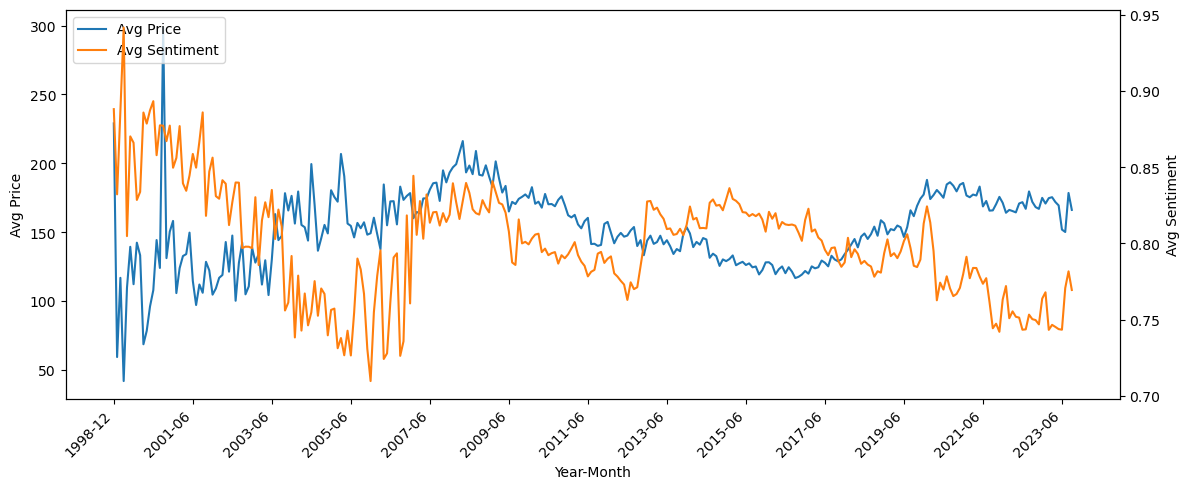

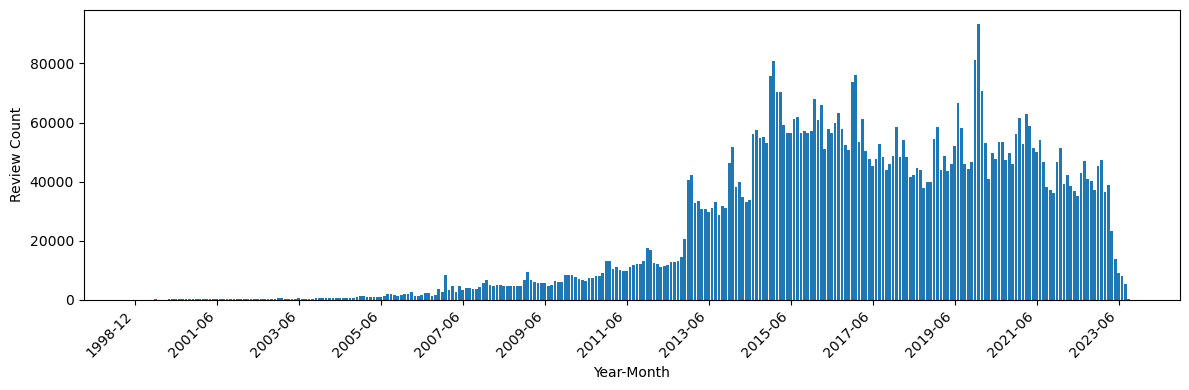

In [12]:
# Example Data Visualization
# ==========================================
import matplotlib.pyplot as plt

pricing_trends_out = "/ecommerce/warehouse/pricing_trends"
sentiment_monthly_out = "/ecommerce/warehouse/sentiment_monthly"

pricing_df = spark.read.parquet(pricing_trends_out)
sent_df = spark.read.parquet(sentiment_monthly_out)

joined = pricing_df.join(sent_df, on="year_month", how="left").orderBy("year_month")
rows = joined.select("year_month", "avg_price", "review_count", "avg_sentiment").collect()

xm = [r["year_month"] for r in rows]
avg_price = [float(r["avg_price"]) if r["avg_price"] is not None else None for r in rows]
review_cnt = [int(r["review_count"]) for r in rows]
avg_sent = [float(r["avg_sentiment"]) if r["avg_sentiment"] is not None else None for r in rows]

positions = list(range(len(xm)))
n = len(positions)
stride = max(1, n // 12)
tick_pos = positions[::stride]
tick_labels = [xm[i] for i in tick_pos]
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(positions, avg_price, label="Avg Price")
ax1.set_xticks(tick_pos)
ax1.set_xticklabels(tick_labels, rotation=45, ha="right")
ax1.set_xlabel("Year-Month")
ax1.set_ylabel("Avg Price")

ax2 = ax1.twinx()
if any(v is not None for v in avg_sent):
    ax2.plot(positions, avg_sent, color="tab:orange", label="Avg Sentiment")
    ax2.set_ylabel("Avg Sentiment")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(positions, review_cnt)
ax.set_xticks(tick_pos)
ax.set_xticklabels(tick_labels, rotation=45, ha="right")
ax.set_xlabel("Year-Month")
ax.set_ylabel("Review Count")
plt.tight_layout()
plt.show()

In [13]:
%pip install openpyxl

Could not fetch URL https://pypi.org/simple/pip/: There was a problem confirming the ssl certificate: HTTPSConnectionPool(host='pypi.org', port=443): Max retries exceeded with url: /simple/pip/ (Caused by SSLError(SSLEOFError(8, '[SSL: UNEXPECTED_EOF_WHILE_READING] EOF occurred in violation of protocol (_ssl.c:1006)'))) - skipping
Note: you may need to restart the kernel to use updated packages.


In [15]:
from datetime import date, datetime

from openpyxl import Workbook
from openpyxl.cell.cell import ILLEGAL_CHARACTERS_RE
from pyspark.sql import functions as F
from pyspark.sql import types as T

meta_src = "/ecommerce/data_lake/meta/*"
out_path = "/home/jovyan/work/metadata_full_all_columns.xlsx"

max_str_len = 32767

def _sanitize_cell(v):
    if v is None:
        return None
    if isinstance(v, str):
        return ILLEGAL_CHARACTERS_RE.sub("", v)[:max_str_len]
    if isinstance(v, (int, float, bool, date, datetime)):
        return v
    return ILLEGAL_CHARACTERS_RE.sub("", str(v))[:max_str_len]

df = spark.read.parquet(meta_src)

# Convert non-scalar columns to JSON strings so they can be written into Excel
for field in df.schema.fields:
    dt = field.dataType
    if isinstance(dt, (T.ArrayType, T.MapType, T.StructType)):
        df = df.withColumn(field.name, F.to_json(F.col(field.name)))
    elif isinstance(dt, T.BinaryType):
        df = df.withColumn(field.name, F.base64(F.col(field.name)))

cols = df.columns
df = df.select(*cols)
total = df.count()
print(f"Exporting metadata rows: {total:,}")
print(f"Columns ({len(cols)}): {cols}")

wb = Workbook(write_only=True)
ws = wb.create_sheet(title="meta")
ws.append(cols)
written = 0
for r in df.toLocalIterator():
    ws.append([_sanitize_cell(v) for v in list(r)])
    written += 1
    if written % 50000 == 0:
        print(f"Wrote rows: {written:,}")

wb.save(out_path)
print(out_path)

Exporting metadata rows: 146,229
Columns: ['parent_asin', 'title', 'price', 'store', 'main_category', 'average_rating', 'rating_number', 'details']
Wrote rows: 50,000
Wrote rows: 100,000
/home/jovyan/work/metadata_full.xlsx
